In [49]:
import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
train = pd.read_csv(url)
test = pd.read_csv("test.csv")
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [51]:
modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)

In [52]:
train["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [53]:
def transformar_sexo(valor):
    if valor == "female":
        return 1
    else:
        return 0

In [54]:
train["Sex_binario"] = train["Sex"].map(transformar_sexo)
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_binario
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0


In [55]:
variaveis = ["Sex_binario", "Age"]

In [56]:
X = train[variaveis]
y = train["Survived"]

In [57]:
X = X.fillna(-1)

In [58]:
modelo.fit(X, y)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [59]:
test["Sex_binario"] = test["Sex"].map(transformar_sexo)

In [60]:
X_prev = test[variaveis]
X_prev = X_prev.fillna(-1)
X_prev.head()

,Sex_binario,Age
0,0,34.5
1,1,47.0
2,0,62.0
3,0,27.0
4,1,22.0


In [61]:
p = modelo.predict(X_prev)

In [62]:
sub = pd.Series(p, index=test["PassengerId"])
sub.shape

(418,)

In [63]:
X_treino, X_validacao, y_treino, y_validacao = train_test_split(X, y, test_size=0.5, random_state=0)

In [64]:
X_treino

,Sex_binario,Age
213,0,30.0
586,0,47.0
499,0,24.0
821,0,27.0
246,1,25.0
...,...,...
835,1,39.0
192,1,19.0
629,0,-1.0
559,1,36.0


In [65]:
modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
modelo.fit(X_treino, y_treino)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [66]:
p = modelo.predict(X_validacao)

In [67]:
import numpy as np

In [68]:
np.mean(y_validacao == p)

np.float64(0.7690582959641256)

In [69]:
p = (X_validacao["Sex_binario"] == 1).astype(int)

In [70]:
np.mean(y_validacao == p)

np.float64(0.7825112107623319)

In [71]:
from sklearn.model_selection import KFold

In [72]:
resultados = []

for rep in range(10):
    print("Rep:", rep)
    kf = KFold(n_splits=2, shuffle=True, random_state=0)

    for linhas_treino, linhas_validacao in kf.split(X):
        print("Treino:", linhas_treino.shape[0])
        print("Teste:", linhas_validacao.shape[0])

        X_treino, X_validacao = X.iloc[linhas_treino], X.iloc[linhas_validacao]
        y_treino, y_validacao = y.iloc[linhas_treino], y.iloc[linhas_validacao]

        modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
        modelo.fit(X_treino, y_treino)

        p = modelo.predict(X_validacao)

        acc = np.mean(y_validacao == p)
        resultados.append(acc)
        print("Acurácia:", acc)
        print()




Rep: 0
Treino: 445
Teste: 446
Acurácia: 0.7713004484304933

Treino: 446
Teste: 445
Acurácia: 0.7797752808988764

Rep: 1
Treino: 445
Teste: 446
Acurácia: 0.7713004484304933

Treino: 446
Teste: 445
Acurácia: 0.7797752808988764

Rep: 2
Treino: 445
Teste: 446
Acurácia: 0.7713004484304933

Treino: 446
Teste: 445
Acurácia: 0.7797752808988764

Rep: 3
Treino: 445
Teste: 446
Acurácia: 0.7713004484304933

Treino: 446
Teste: 445
Acurácia: 0.7797752808988764

Rep: 4
Treino: 445
Teste: 446
Acurácia: 0.7713004484304933

Treino: 446
Teste: 445
Acurácia: 0.7797752808988764

Rep: 5
Treino: 445
Teste: 446
Acurácia: 0.7713004484304933

Treino: 446
Teste: 445
Acurácia: 0.7797752808988764

Rep: 6
Treino: 445
Teste: 446
Acurácia: 0.7713004484304933

Treino: 446
Teste: 445
Acurácia: 0.7797752808988764

Rep: 7
Treino: 445
Teste: 446
Acurácia: 0.7713004484304933

Treino: 446
Teste: 445
Acurácia: 0.7797752808988764

Rep: 8
Treino: 445
Teste: 446
Acurácia: 0.7713004484304933

Treino: 446
Teste: 445
Acurácia: 0.7

In [73]:
np.mean(resultados)

np.float64(0.7755378646646849)

In [74]:
from sklearn.model_selection import RepeatedKFold

In [75]:
resultados = []
kf = RepeatedKFold(n_splits=2, n_repeats=10, random_state=42)

for linhas_treino, linhas_validacao in kf.split(X):
    print("Treino:", linhas_treino.shape[0])
    print("Teste:", linhas_validacao.shape[0])

    X_treino, X_validacao = X.iloc[linhas_treino], X.iloc[linhas_validacao]
    y_treino, y_validacao = y.iloc[linhas_treino], y.iloc[linhas_validacao]

    modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
    modelo.fit(X_treino, y_treino)

    p = modelo.predict(X_validacao)

    acc = np.mean(y_validacao == p)
    resultados.append(acc)

    print("Acurácia:", acc)
    print()


Treino: 445
Teste: 446
Acurácia: 0.7690582959641256

Treino: 446
Teste: 445
Acurácia: 0.7595505617977528

Treino: 445
Teste: 446
Acurácia: 0.7869955156950673

Treino: 446
Teste: 445
Acurácia: 0.7640449438202247

Treino: 445
Teste: 446
Acurácia: 0.7600896860986547

Treino: 446
Teste: 445
Acurácia: 0.7370786516853932

Treino: 445
Teste: 446
Acurácia: 0.7488789237668162

Treino: 446
Teste: 445
Acurácia: 0.7573033707865169

Treino: 445
Teste: 446
Acurácia: 0.757847533632287

Treino: 446
Teste: 445
Acurácia: 0.7640449438202247

Treino: 445
Teste: 446
Acurácia: 0.7690582959641256

Treino: 446
Teste: 445
Acurácia: 0.7617977528089888

Treino: 445
Teste: 446
Acurácia: 0.7488789237668162

Treino: 446
Teste: 445
Acurácia: 0.7573033707865169

Treino: 445
Teste: 446
Acurácia: 0.7600896860986547

Treino: 446
Teste: 445
Acurácia: 0.7573033707865169

Treino: 445
Teste: 446
Acurácia: 0.7757847533632287

Treino: 446
Teste: 445
Acurácia: 0.7662921348314606

Treino: 445
Teste: 446
Acurácia: 0.775784753363

In [76]:
np.mean(resultados)

np.float64(0.761162644228347)

In [77]:
import matplotlib.pyplot as plt

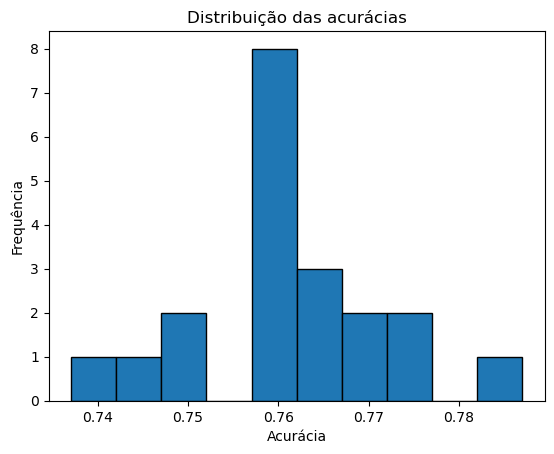

In [78]:
plt.hist(resultados, bins=10, edgecolor="black")
plt.xlabel("Acurácia")
plt.ylabel("Frequência")
plt.title("Distribuição das acurácias")
plt.show()

In [79]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_binario
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0


In [80]:
variaveis = ["Sex_binario", "Age", "Pclass", "SibSp", "Parch", "Fare"]

In [81]:
X = train[variaveis].fillna(-1)
y = train["Survived"]

In [82]:
resultados = []
kf = RepeatedKFold(n_splits=2, n_repeats=10, random_state=42)

for linhas_treino, linhas_validacao in kf.split(X):
    print("Treino:", linhas_treino.shape[0])
    print("Teste:", linhas_validacao.shape[0])

    X_treino, X_validacao = X.iloc[linhas_treino], X.iloc[linhas_validacao]
    y_treino, y_validacao = y.iloc[linhas_treino], y.iloc[linhas_validacao]

    modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
    modelo.fit(X_treino, y_treino)

    p = modelo.predict(X_validacao)

    acc = np.mean(y_validacao == p)
    resultados.append(acc)

    print("Acurácia:", acc)
    print()

Treino: 445
Teste: 446
Acurácia: 0.8318385650224215

Treino: 446
Teste: 445
Acurácia: 0.8067415730337079

Treino: 445
Teste: 446
Acurácia: 0.7757847533632287

Treino: 446
Teste: 445
Acurácia: 0.8292134831460675

Treino: 445
Teste: 446
Acurácia: 0.7982062780269058

Treino: 446
Teste: 445
Acurácia: 0.8337078651685393

Treino: 445
Teste: 446
Acurácia: 0.7892376681614349

Treino: 446
Teste: 445
Acurácia: 0.8337078651685393

Treino: 445
Teste: 446
Acurácia: 0.8228699551569507

Treino: 446
Teste: 445
Acurácia: 0.7887640449438202

Treino: 445
Teste: 446
Acurácia: 0.804932735426009

Treino: 446
Teste: 445
Acurácia: 0.8067415730337079

Treino: 445
Teste: 446
Acurácia: 0.7914798206278026

Treino: 446
Teste: 445
Acurácia: 0.797752808988764

Treino: 445
Teste: 446
Acurácia: 0.7982062780269058

Treino: 446
Teste: 445
Acurácia: 0.802247191011236

Treino: 445
Teste: 446
Acurácia: 0.8161434977578476

Treino: 446
Teste: 445
Acurácia: 0.7730337078651686

Treino: 445
Teste: 446
Acurácia: 0.80941704035874

In [83]:
np.mean(resultados)

np.float64(0.8048271779110193)

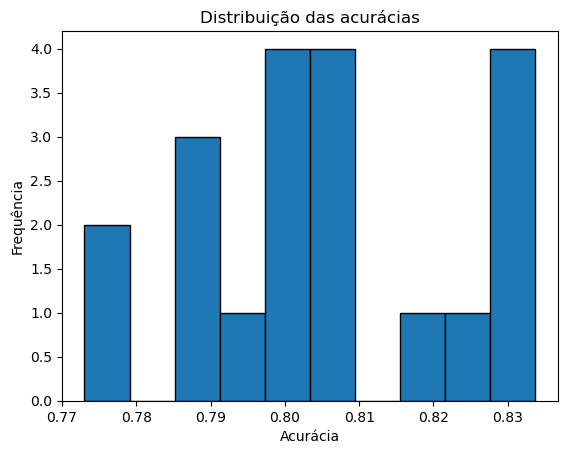

In [84]:
plt.hist(resultados, bins=10, edgecolor="black")
plt.xlabel("Acurácia")
plt.ylabel("Frequência")
plt.title("Distribuição das acurácias")
plt.show()

In [86]:
# Retreinar o modelo
modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
modelo.fit(X, y)

p = modelo.predict(test[variaveis].fillna(-1))

In [87]:
# Análise erro

resultados = []
kf = RepeatedKFold(n_splits=2, n_repeats=10, random_state=42)

for linhas_treino, linhas_validacao in kf.split(X):
    print("Treino:", linhas_treino.shape[0])
    print("Teste:", linhas_validacao.shape[0])

    X_treino, X_validacao = X.iloc[linhas_treino], X.iloc[linhas_validacao]
    y_treino, y_validacao = y.iloc[linhas_treino], y.iloc[linhas_validacao]

    modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
    modelo.fit(X_treino, y_treino)

    p = modelo.predict(X_validacao)

    acc = np.mean(y_validacao == p)
    resultados.append(acc)

    print("Acurácia:", acc)
    print()

Treino: 445
Teste: 446
Acurácia: 0.8318385650224215

Treino: 446
Teste: 445
Acurácia: 0.8067415730337079

Treino: 445
Teste: 446
Acurácia: 0.7757847533632287

Treino: 446
Teste: 445
Acurácia: 0.8292134831460675

Treino: 445
Teste: 446
Acurácia: 0.7982062780269058

Treino: 446
Teste: 445
Acurácia: 0.8337078651685393

Treino: 445
Teste: 446
Acurácia: 0.7892376681614349

Treino: 446
Teste: 445
Acurácia: 0.8337078651685393

Treino: 445
Teste: 446
Acurácia: 0.8228699551569507

Treino: 446
Teste: 445
Acurácia: 0.7887640449438202

Treino: 445
Teste: 446
Acurácia: 0.804932735426009

Treino: 446
Teste: 445
Acurácia: 0.8067415730337079

Treino: 445
Teste: 446
Acurácia: 0.7914798206278026

Treino: 446
Teste: 445
Acurácia: 0.797752808988764

Treino: 445
Teste: 446
Acurácia: 0.7982062780269058

Treino: 446
Teste: 445
Acurácia: 0.802247191011236

Treino: 445
Teste: 446
Acurácia: 0.8161434977578476

Treino: 446
Teste: 445
Acurácia: 0.7730337078651686

Treino: 445
Teste: 446
Acurácia: 0.80941704035874

In [88]:
X_validacao_check = train.iloc[linhas_validacao].copy()
X_validacao_check["prev"] = p
X_validacao_check.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_binario,prev
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1,1
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,0,0
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S,1,1
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S,1,1
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S,1,1


In [92]:
erros = X_validacao_check[X_validacao_check["Survived"] != X_validacao_check["prev"]]
erros = erros[["PassengerId", "Pclass", "Name", "Sex", "Age", "SibSp", "Parch", "Ticket", "Fare", "Cabin", "Embarked", "Sex_binario", "prev", "Survived"]]
erros.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_binario,prev,Survived
17,18,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S,0,0,1
18,19,3,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",female,31.0,1,0,345763,18.0000,NaN,S,1,1,0
25,26,3,"Asplund, Mrs. Carl Oscar (Selma Augusta Emilia...",female,38.0,1,5,347077,31.3875,NaN,S,1,0,1
33,34,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,NaN,S,0,1,0
49,50,3,"Arnold-Franchi, Mrs. Josef (Josefine Franchi)",female,18.0,1,0,349237,17.8000,NaN,S,1,1,0


In [93]:
mulheres = erros[erros["Sex"] == "female"]
homens = erros[erros["Sex"] == "male"]

In [94]:
mulheres.sort_values("Survived")

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_binario,prev,Survived
18,19,3,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",female,31.0,1,0,345763,18.0000,NaN,S,1,1,0
49,50,3,"Arnold-Franchi, Mrs. Josef (Josefine Franchi)",female,18.0,1,0,349237,17.8000,NaN,S,1,1,0
111,112,3,"Zabour, Miss. Hileni",female,14.5,1,0,2665,14.4542,NaN,C,1,1,0
100,101,3,"Petranec, Miss. Matilda",female,28.0,0,0,349245,7.8958,NaN,S,1,1,0
114,115,3,"Attalah, Miss. Malake",female,17.0,0,0,2627,14.4583,NaN,C,1,1,0
235,236,3,"Harknett, Miss. Alice Phoebe",female,NaN,0,0,W./C. 6609,7.5500,NaN,S,1,1,0
177,178,1,"Isham, Miss. Ann Elizabeth",female,50.0,0,0,PC 17595,28.7125,C49,C,1,1,0
140,141,3,"Boulos, Mrs. Joseph (Sultana)",female,NaN,0,2,2678,15.2458,NaN,C,1,1,0
240,241,3,"Zabour, Miss. Thamine",female,NaN,1,0,2665,14.4542,NaN,C,1,1,0
199,200,2,"Yrois, Miss. Henriette (""Mrs Harbeck"")",female,24.0,0,0,248747,13.0000,NaN,S,1,1,0


In [97]:
train["Embarked_S"] = (train["Embarked"] == "S").astype(int)
train["Embarked_C"] = (train["Embarked"] == "C").astype(int)
#train["Embarked_Q"] = (train["Embarked"] == "Q").astype(int)

train["Cabine_nula"] = train["Cabin"].isnull().astype(int)

train["Nome_contem_Miss"] = train["Name"].str.contains(r", Miss\.").astype(int)
train["Nome_contem_Mrs"] = train["Name"].str.contains(r", Mrs\.").astype(int)

train["Nome_contem_Master"] = train["Name"].str.contains(r", Master\.").astype(int)
train["Nome_contem_Col"] = train["Name"].str.contains(r", Col\.").astype(int)
train["Nome_contem_Major"] = train["Name"].str.contains(r", Major\.").astype(int)
train["Nome_contem_Mr"] = train["Name"].str.contains(r", Mr\.").astype(int)

In [95]:
variaveis

['Sex_binario', 'Age', 'Pclass', 'SibSp', 'Parch', 'Fare']

In [98]:
variaveis = ['Sex_binario', 'Age', 'Pclass', 'SibSp', 'Parch', 'Fare', 'Embarked_S', 'Embarked_C', 'Cabine_nula', 'Nome_contem_Miss', 'Nome_contem_Mrs', 'Nome_contem_Master', 'Nome_contem_Col', 'Nome_contem_Major', 'Nome_contem_Mr']

X = train[variaveis].fillna(-1)
y = train["Survived"]

In [99]:
resultados2 = []
kf = RepeatedKFold(n_splits=2, n_repeats=10, random_state=42)

for linhas_treino, linhas_validacao in kf.split(X):
    print("Treino:", linhas_treino.shape[0])
    print("Teste:", linhas_validacao.shape[0])

    X_treino, X_validacao = X.iloc[linhas_treino], X.iloc[linhas_validacao]
    y_treino, y_validacao = y.iloc[linhas_treino], y.iloc[linhas_validacao]

    modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
    modelo.fit(X_treino, y_treino)

    p = modelo.predict(X_validacao)

    acc = np.mean(y_validacao == p)
    resultados2.append(acc)

    print("Acurácia:", acc)
    print()

Treino: 445
Teste: 446
Acurácia: 0.8116591928251121

Treino: 446
Teste: 445
Acurácia: 0.8112359550561797

Treino: 445
Teste: 446
Acurácia: 0.804932735426009

Treino: 446
Teste: 445
Acurácia: 0.8269662921348314

Treino: 445
Teste: 446
Acurácia: 0.7892376681614349

Treino: 446
Teste: 445
Acurácia: 0.8179775280898877

Treino: 445
Teste: 446
Acurácia: 0.7937219730941704

Treino: 446
Teste: 445
Acurácia: 0.8269662921348314

Treino: 445
Teste: 446
Acurácia: 0.8295964125560538

Treino: 446
Teste: 445
Acurácia: 0.7887640449438202

Treino: 445
Teste: 446
Acurácia: 0.8139013452914798

Treino: 446
Teste: 445
Acurácia: 0.8112359550561797

Treino: 445
Teste: 446
Acurácia: 0.7914798206278026

Treino: 446
Teste: 445
Acurácia: 0.7932584269662921

Treino: 445
Teste: 446
Acurácia: 0.8004484304932735

Treino: 446
Teste: 445
Acurácia: 0.8269662921348314

Treino: 445
Teste: 446
Acurácia: 0.8026905829596412

Treino: 446
Teste: 445
Acurácia: 0.7910112359550562

Treino: 445
Teste: 446
Acurácia: 0.816143497757

In [100]:
np.mean(resultados2)

np.float64(0.8075220436337986)

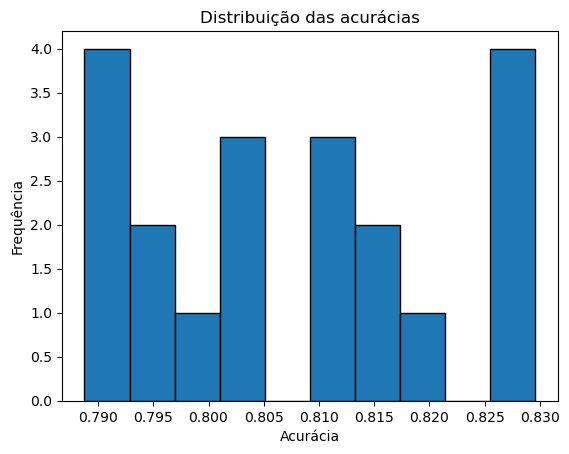

In [101]:
plt.hist(resultados2, bins=10, edgecolor="black")
plt.xlabel("Acurácia")
plt.ylabel("Frequência")
plt.title("Distribuição das acurácias")
plt.show()

In [102]:
test["Embarked_S"] = (test["Embarked"] == "S").astype(int)
test["Embarked_C"] = (test["Embarked"] == "C").astype(int)
#test["Embarked_Q"] = (test["Embarked"] == "Q").astype(int)

test["Cabine_nula"] = test["Cabin"].isnull().astype(int)

test["Nome_contem_Miss"] = test["Name"].str.contains(r", Miss\.").astype(int)
test["Nome_contem_Mrs"] = test["Name"].str.contains(r", Mrs\.").astype(int)

test["Nome_contem_Master"] = test["Name"].str.contains(r", Master\.").astype(int)
test["Nome_contem_Col"] = test["Name"].str.contains(r", Col\.").astype(int)
test["Nome_contem_Major"] = test["Name"].str.contains(r", Major\.").astype(int)
test["Nome_contem_Mr"] = test["Name"].str.contains(r", Mr\.").astype(int)

modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
modelo.fit(X, y)

p = modelo.predict(test[variaveis].fillna(-1))

In [103]:
from sklearn.linear_model import LogisticRegression

In [104]:
resultados2 = []
kf = RepeatedKFold(n_splits=2, n_repeats=10, random_state=42)

for linhas_treino, linhas_validacao in kf.split(X):
    print("Treino:", linhas_treino.shape[0])
    print("Teste:", linhas_validacao.shape[0])

    X_treino, X_validacao = X.iloc[linhas_treino], X.iloc[linhas_validacao]
    y_treino, y_validacao = y.iloc[linhas_treino], y.iloc[linhas_validacao]

    modelo = LogisticRegression()
    modelo.fit(X_treino, y_treino)

    p = modelo.predict(X_validacao)

    acc = np.mean(y_validacao == p)
    resultados2.append(acc)

    print("Acurácia:", acc)
    print()

Treino: 445
Teste: 446
Acurácia: 0.8139013452914798

Treino: 446
Teste: 445
Acurácia: 0.8292134831460675

Treino: 445
Teste: 446
Acurácia: 0.8094170403587444

Treino: 446
Teste: 445


c:\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation f

Acurácia: 0.8247191011235955

Treino: 445
Teste: 446
Acurácia: 0.8161434977578476

Treino: 446
Teste: 445
Acurácia: 0.8314606741573034

Treino: 445
Teste: 446
Acurácia: 0.804932735426009

Treino: 446
Teste: 445
Acurácia: 0.8292134831460675

Treino: 445
Teste: 446
Acurácia: 0.8475336322869955

Treino: 446
Teste: 445
Acurácia: 0.8

Treino: 445
Teste: 446
Acurácia: 0.8318385650224215

Treino: 446
Teste: 445
Acurácia: 0.8224719101123595

Treino: 445
Teste: 446
Acurácia: 0.8340807174887892

Treino: 446
Teste: 445
Acurácia: 0.8224719101123595

Treino: 445
Teste: 446
Acurácia: 0.820627802690583

Treino: 446
Teste: 445
Acurácia: 0.8224719101123595

Treino: 445
Teste: 446
Acurácia: 0.8475336322869955

Treino: 446
Teste: 445
Acurácia: 0.7932584269662921

Treino: 445
Teste: 446
Acurácia: 0.8318385650224215

Treino: 446
Teste: 445
Acurácia: 0.8112359550561797



c:\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation f

In [105]:
np.mean(resultados2)

np.float64(0.8222182193782436)

In [108]:
test["Embarked_S"] = (test["Embarked"] == "S").astype(int)
test["Embarked_C"] = (test["Embarked"] == "C").astype(int)
#test["Embarked_Q"] = (test["Embarked"] == "Q").astype(int)

test["Cabine_nula"] = test["Cabin"].isnull().astype(int)

test["Nome_contem_Miss"] = test["Name"].str.contains(r", Miss\.").astype(int)
test["Nome_contem_Mrs"] = test["Name"].str.contains(r", Mrs\.").astype(int)

test["Nome_contem_Master"] = test["Name"].str.contains(r", Master\.").astype(int)
test["Nome_contem_Col"] = test["Name"].str.contains(r", Col\.").astype(int)
test["Nome_contem_Major"] = test["Name"].str.contains(r", Major\.").astype(int)
test["Nome_contem_Mr"] = test["Name"].str.contains(r", Mr\.").astype(int)

modelo = LogisticRegression()
modelo.fit(X, y)

p = modelo.predict(test[variaveis].fillna(-1))

c:\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [109]:
sub = pd.Series(p, index=test['PassengerId'], name="Survived")
sub.shape

(418,)

In [111]:
sub.to_csv("regrassao_logistic_definitive.csv", header=True)